In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,r2_score

In [5]:
housing=fetch_california_housing()
data=pd.DataFrame(housing.data,
                  columns=housing.feature_names)
data["Price"]=housing.target

In [6]:
x=data[['AveRooms']].values
y=data['Price'].values

In [7]:
x_train,x_test,y_train,y_test=train_test_split(x,y,
                                               test_size=0.2,
                                               random_state=42
                                              )

In [8]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [78]:
w=0
b=0
learning_rate=0.01
epochs=1000
cost_history=[]
n=len(x_train_scaled)
for i in range(epochs):
    y_pred=w*x_train_scaled.flatten()+b
    dw=(1/n)*np.sum((y_pred-y_train)*x_train_scaled.flatten())
    db=(1/n)*np.sum(y_pred-y_train)
    w=w-learning_rate*dw
    b=b-learning_rate*db
    cost=(1/(2*n))*np.sum((y_pred-y_train)**2)
    cost_history.append(cost)
    if i%100==0:
        print(f"Epoch {i},Cost={cost:4f}")
y_pred_gd=w*x_test_scaled.flatten() +b

Epoch 0,Cost=2.814871
Epoch 100,Cost=0.941435
Epoch 200,Cost=0.690433
Epoch 300,Cost=0.656804
Epoch 400,Cost=0.652298
Epoch 500,Cost=0.651694
Epoch 600,Cost=0.651613
Epoch 700,Cost=0.651603
Epoch 800,Cost=0.651601
Epoch 900,Cost=0.651601


In [79]:
print("gradiant Descent")
print("----------------")
print("Weight:",w)
print("Bias:",b)
print("MSE:",mean_squared_error(y_test,y_pred_gd))
print("R2 score: ",r2_score(y_test,y_pred_gd))

gradiant Descent
----------------
Weight: 0.18323090648660517
Bias: 2.0718574888450205
MSE: 1.292327655590046
R2 score:  0.013798228607320828


In [80]:
print(w,"x+",b)

0.18323090648660517 x+ 2.0718574888450205


In [81]:
##normal equation

In [82]:
x_train_ne=np.c_[np.ones((len(x_train),1)),x_train]
x_test_ne=np.c_[np.ones((len(x_test),1)),x_test]
theta=np.linalg.inv(x_train_ne.T @ x_train_ne) @x_train_ne.T @ y_train
y_pred_ne=x_test_ne @ theta

In [83]:
print("Normal equation")
print("------------------")
print("Intercept:",theta[0])
print("slope:",theta[1])
print("MSE:",mean_squared_error(y_test,y_pred_ne))
print("R2 Score:",r2_score(y_test,y_pred_ne))

Normal equation
------------------
Intercept: 1.6547622685968417
slope: 0.07675558963126736
MSE: 1.2923314440807299
R2 Score: 0.013795337532284901


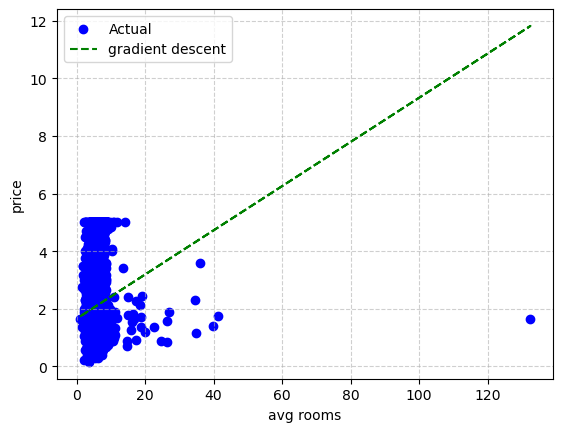

In [84]:
plt.scatter(x_test,y_test,color="blue",label="Actual")
plt.plot(x_test,y_pred_gd,color="green",linestyle="--",label="gradient descent")
plt.grid(True,linestyle='--',alpha=0.6)
plt.xlabel("avg rooms")
plt.ylabel("price")
plt.legend()
plt.show()

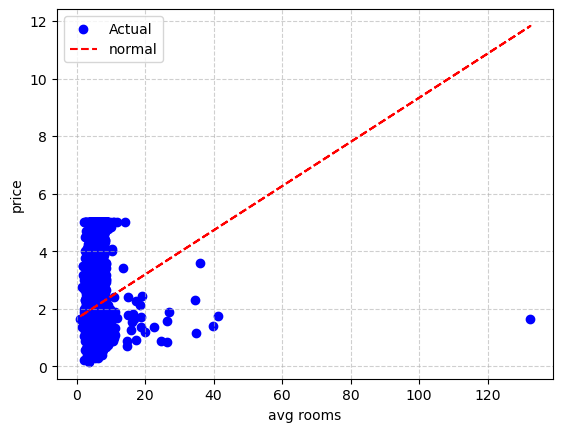

In [85]:
plt.scatter(x_test,y_test,color="blue",label="Actual")
plt.plot(x_test,y_pred_ne,color="red",linestyle="--",label="normal")
plt.grid(True,linestyle='--',alpha=0.6)
plt.xlabel("avg rooms")
plt.ylabel("price")
plt.legend()
plt.show()

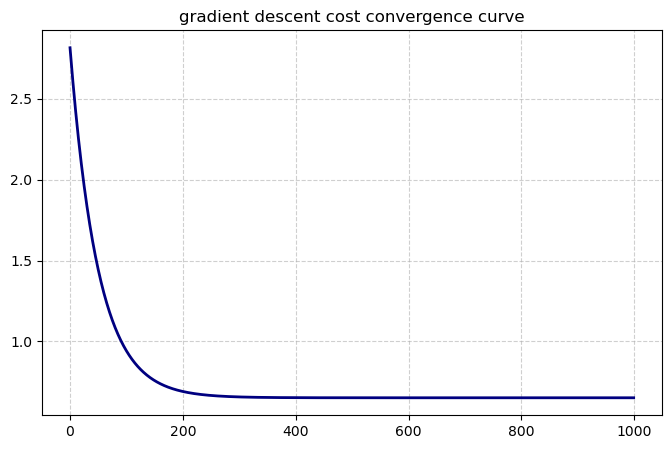

In [86]:

plt.figure(figsize=(8,5))
plt.plot(cost_history,color='navy',linewidth=2)
plt.title("gradient descent cost convergence curve")
plt.grid(True,linestyle='--',alpha=0.6)
plt.show()

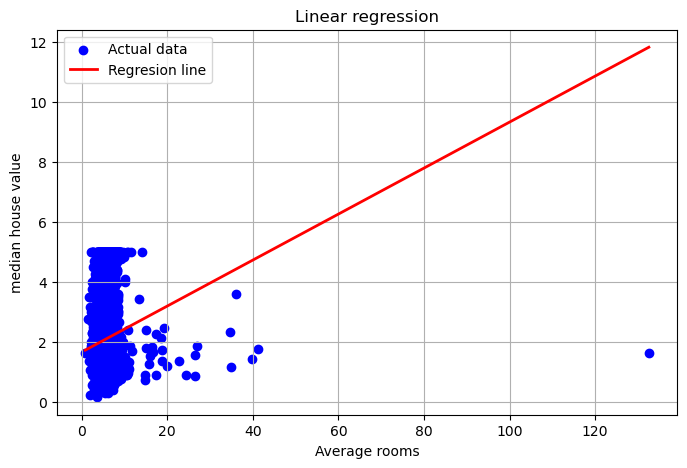

In [87]:
index=np.argsort(x_test.flatten())
plt.figure(figsize=(8,5))
plt.scatter(x_test,y_test,color='blue',label='Actual data')
plt.plot(x_test.flatten()[index],y_pred_ne[index],color='red',linewidth=2,
         label="Regresion line")
plt.title("Linear regression")
plt.xlabel("Average rooms")
plt.ylabel("median house value")
plt.legend()
plt.grid(True)
plt.show()